# Diurnal cycle of isoprene emission: fixed-BVOC (fBVOC) runs

Companion of `isoprene_diurnal_cycle.ipynb` (interactive MEGAN), same figures for the **prescribed isoprene** of the fBVOC runs, plus the **full time series at hourly resolution** (interactive and prescribed).

**What the fBVOC runs receive.** MEGAN is off and ISOP is read from `ems_<source>_2001-2014_SFISOP.nc` (`/cluster/shared/noresm/inputdata/atm/cam/prescribed_data/bvoc_emissions/`): one cyclic year of 30-min records, the 2001–2014 mean of the source run for each day-of-year and step. CAM's isoprene diurnal rescaling is bypassed (`cases-scripts/bypass_isoprene_diurnal_adjustment.py`), so the model emits the file value. Checked (a): `CTRL_PD_fBVOCctrlPD_HR` h1 `SFISOP` = its source `CTRL_PD -20261023` h1 to 0.05 % (60°N 30°E, 1 Jul 2001, same time stamps as the file). The production fBVOC runs have no 30-min output, so their flux is taken **from the input files**:

| Input (alias here) | Source case | Used by |
|---|---|---|
| `CTRL_PD` | `NF2000…nudg_ctrl_f19_f19-20261029` | `LCC_PD_fBVOCctrlPD`, `CTRL_PD_fBVOCctrlPD`, `LCC_FUT_fBVOCctrlPD` (relabelled to 2100) |
| `LCC_PD` | `NF2000…nudg_lcc_f19_f19-20261028` | `LCC_PD_fBVOClccPD`, `LCC_FUT_fBVOClccPD` |
| `CTRL_FUT` | `NF2100ssp585…nudg_ctrl_f19_f19-20261028` | `LCC_FUT_fBVOCctrlFUT`, `CTRL_FUT_fBVOCctrlFUT` |
| `LCC_FUT` | `NF2100ssp585…nudg_lcc_f19_f19-20261028` (via `LCC_FUT_HRBVOC`) | `LCC_FUT_fBVOClccFUT` |

So here "LCC − CTRL" of the prescribed input is the emission difference of the design-A contrast `LCC_P_fBVOClccP − CTRL_P_fBVOCctrlP`.

**fBVOC runs with real 30-min output** (old-chain 3-yr tests, years 2001–2002): `CTRL_PD_fBVOCctrlPD_HR` (replay of each year's emissions) and `CTRL_PD_fBVOCctrlPD_C0102` (2001–02 climatology), against their MEGAN source `CTRL_PD -20261023` (alias `CTRL_PD_old` here). Section 8.

**Inputs** (from `reduce_isoprene_fbvoc_and_timeseries.py`, this folder): `data/processed-data/isoprene-diurnal/fbvoc/diurnal_*.nc` (monthly diurnal composites, same layout as the interactive ones) and `…/timeseries/ts_*.nc` (regional totals every 30 min, UTC). Interactive reference = the MEGAN exact-split branch composites of `isoprene_diurnal_cycle.ipynb`.

**Choices** (as in the interactive notebook)
- Record stamped *t* = flux of the step ending at *t*, assigned to the step centre *t* − 15 min (same for the input files, whose stamps are the h1 stamps).
- Local solar time = UTC + lon/15 h, rounded to the 30-min step. Regional values are totals (flux × grid-cell area), Mg h⁻¹.
- Regions: LCC-modified cells (`diagnostics/lcc-modified-cells/modified_cells.nc`) and all cells ≥ 45°N.
- The prescribed input is one climatological year: no year-to-year spread. Interactive lines/shading are shown for reference (thin lines = mean over years; Δ shading = 95 % t-interval of the paired yearly differences).
- Time series: hourly = mean of the two 30-min steps, **UTC** (regional totals span many longitudes, so local time is not defined for them).

**Section 10: each production fBVOC run against its own interactive source** (source 30-min output 2001–2014, monthly 2001–2025; `reduce_isoprene_fbvoc_vs_source.py`).

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
from scipy import stats

ROOT = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
IN_DIR = ROOT / "data/processed-data/isoprene-diurnal"
FB_DIR, TS_DIR = IN_DIR / "fbvoc", IN_DIR / "timeseries"
MASK = ROOT / "diagnostics/lcc-modified-cells/modified_cells.nc"
OUT = ROOT / "diagnostics/2_isoprene-diurnal-cycle/isoprene_diurnal_cycle_fBVOC_outputs"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(parents=True, exist_ok=True)

# project palette (src/boreal_forest_expansion/plotting/palette.py), in order; gold = total
TEAL, NAVY, PLUM, RED, ORANGE, GOLD, LGREY = "#5D9A92", "#2C3990", "#9A4A84", "#BC423E", "#DE7A3A", "#EBC45C", "#CCCCCC"
COL = {"CTRL": NAVY, "LCC": RED}
LS = {"PD": "-", "FUT": "--"}
TESTS = {"CTRL_PD_old": NAVY, "CTRL_PD_fBVOCctrlPD_HR": TEAL, "CTRL_PD_fBVOCctrlPD_C0102": PLUM}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
SEASONS = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}
DAYS = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

def load_nc(path, tries=8, **kw):
    # NIRD, 16 Nov 2026: ~5 % of reads fail with 'NetCDF: HDF error' on intact files (same md5; 0 % from /cluster/work)
    for k in range(tries):
        try:
            with xr.open_dataset(path, **kw) as ds:
                return ds.load()
        except RuntimeError:
            if k == tries - 1:
                raise


## 1. Load the composites

In [2]:
# prescribed inputs: one cyclic year each
EMS = {}
for f in sorted(FB_DIR.glob("diurnal_ems_*.nc")):
    v, p = f.stem.removeprefix("diurnal_ems_").split("_")
    ds = load_nc(f)
    EMS[(v, p)] = ds.SFISOP
    print(f"input {v}_{p}: {ds.attrs['case']}")

# interactive MEGAN reference (files of isoprene_diurnal_cycle.ipynb), years present for both CTRL and LCC
files = {}
for f in sorted(IN_DIR.glob("diurnal_*_*.nc")):
    m = re.fullmatch(r"diurnal_(CTRL|LCC)_(PD|FUT)_(\d{4})\.nc", f.name)
    if m:
        files[(m[1], m[2], int(m[3]))] = f
YEARS = {per: sorted({y for (v, p, y) in files if v == "CTRL" and p == per} & {y for (v, p, y) in files if v == "LCC" and p == per})
         for per in ("PD", "FUT")}
print("interactive years:", YEARS)
INT = {(v, p): xr.concat([load_nc(files[(v, p, y)]).SFISOP.expand_dims(year=[y]) for y in YEARS[p]], "year")
       for p in YEARS if YEARS[p] for v in ("CTRL", "LCC")}

# fBVOC test runs with 30-min output, and their MEGAN source
TST = {}
for a in TESTS:
    das = []
    for y in (2001, 2002):
        ds = load_nc(FB_DIR / f"diurnal_{a}_{y}.nc")
        das.append(ds.SFISOP.expand_dims(year=[y]))
        print(f"  {a} {y}: {ds.attrs['case']}")
    TST[a] = xr.concat(das, "year")

ref = EMS[("CTRL", "PD")]
lat, lon = ref.lat.values, ref.lon.values
for x in list(EMS.values()) + list(INT.values()) + list(TST.values()):
    assert np.allclose(x.lat, lat) and np.allclose(x.lon, lon) and (x.step.values == ref.step.values).all()

input CTRL_FUT: prescribed input ems_NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028_2001-2014
input CTRL_PD: prescribed input ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029_2001-2014
input LCC_FUT: prescribed input ems_NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014
input LCC_PD: prescribed input ems_NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028_2001-2014
interactive years: {'PD': [2001, 2002, 2005, 2006, 2010, 2011], 'FUT': [2001, 2005, 2010]}
  CTRL_PD_old 2001: NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261023
  CTRL_PD_old 2002: NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261023
  CTRL_PD_fBVOCctrlPD_HR 2001: NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_HR_f19_f19-20261029
  CTRL_PD_fBVOCctrlPD_HR 2002: NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_HR_f19_f19-20261029
  CTRL_PD_fBVOCctrlPD_C0102 2001: NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_C0102_f19_f19-20261109
  CTRL_PD_fBVOCctrlPD_C0102 2002: NF2000norbc_tropstra

## 2. UTC → local solar time, cell areas, regions (as in the interactive notebook)

In [3]:
lon180 = np.where(lon > 180, lon - 360, lon)
shift = np.rint(lon180 / 7.5).astype(int)
idx = (np.arange(48)[:, None] - shift[None, :]) % 48          # (step, lon)

def to_lst(da):
    a = da.values                                              # (..., step, lat, lon)
    ix = np.broadcast_to(idx[:, None, :], a.shape[-3:])
    out = np.take_along_axis(a, np.broadcast_to(ix, a.shape), axis=-3)
    return da.copy(data=out).rename(step="lst")

HOURS = ref.step.values
R = 6.37122e6
lat_e = np.concatenate([[-90], 0.5 * (lat[1:] + lat[:-1]), [90]])
area = (R**2 * np.deg2rad(lon[1] - lon[0]) * np.diff(np.sin(np.deg2rad(lat_e))))[:, None] * np.ones(lon.size)
area = xr.DataArray(area, coords={"lat": lat, "lon": lon}, dims=("lat", "lon"))
mod = load_nc(MASK).modified
assert np.allclose(mod.lat, lat) and np.allclose(mod.lon, lon)
mod = xr.DataArray(mod.values.astype(bool), coords=area.coords)
REGIONS = {"LCC-modified cells": mod,
           "≥ 45°N": xr.DataArray(np.broadcast_to(lat[:, None] >= 45, area.shape), coords=area.coords)}
KG_S_TO_MG_H = 3600 / 1e3

def regional_total(da, mask):
    w = (area * mask).values
    vals = np.tensordot(da.values, w, axes=([-2, -1], [0, 1])) * KG_S_TO_MG_H
    return xr.DataArray(vals, coords={d: da[d] for d in da.dims[:-2]}, dims=da.dims[:-2])

def season_mean(x, months):
    w = xr.DataArray(DAYS[np.array(months) - 1], coords={"month": months})
    return x.sel(month=months).weighted(w).mean("month")

REG_E = {(r, v, p): regional_total(to_lst(x), m) for r, m in REGIONS.items() for (v, p), x in EMS.items()}
REG_I = {(r, v, p): regional_total(to_lst(x), m) for r, m in REGIONS.items() for (v, p), x in INT.items()}
REG_T = {(r, a): regional_total(to_lst(x), m) for r, m in REGIONS.items() for a, x in TST.items()}

### Check: annual totals, prescribed input vs interactive

Tg yr⁻¹ (sum of the 48 half-hour rates × 0.5 h × days). The input is the 2001–2014 mean of the source run; the interactive reference is the mean over the exact-split years, so they differ by interannual sampling, not by method.

In [4]:
MONTH_DAYS = xr.DataArray(DAYS, coords={"month": np.arange(1, 13)})
annual = lambda x: (x.sum("lst") * 0.5 * MONTH_DAYS).sum("month") / 1e6
rows = []
for (r, v, p), x in REG_E.items():
    i = annual(REG_I[(r, v, p)]) if (r, v, p) in REG_I else None
    rows.append(dict(region=r, alias=f"{v}_{p}", prescribed_2001_2014=float(annual(x)),
                     interactive_mean=float(i.mean()) if i is not None else np.nan,
                     interactive_years=",".join(map(str, YEARS[p]))))
tab = pd.DataFrame(rows)
tab["prescribed_over_interactive"] = tab.prescribed_2001_2014 / tab.interactive_mean
tab.round(3).to_csv(OUT / "tables/annual_isoprene_totals_prescribed_vs_interactive_Tg.csv", index=False)
tab.round(3)

,region,alias,prescribed_2001_2014,interactive_mean,interactive_years,prescribed_over_interactive
0,LCC-modified cells,CTRL_FUT,12.491,12.701,"2001,2005,2010",0.983
1,LCC-modified cells,CTRL_PD,4.126,4.070,"2001,2002,2005,2006,2010,2011",1.014
2,LCC-modified cells,LCC_FUT,12.853,13.154,"2001,2005,2010",0.977
3,LCC-modified cells,LCC_PD,4.367,4.301,"2001,2002,2005,2006,2010,2011",1.015
4,≥ 45°N,CTRL_FUT,23.224,23.773,"2001,2005,2010",0.977
5,≥ 45°N,CTRL_PD,9.359,9.376,"2001,2002,2005,2006,2010,2011",0.998
6,≥ 45°N,LCC_FUT,23.612,24.229,"2001,2005,2010",0.975
7,≥ 45°N,LCC_PD,9.645,9.643,"2001,2002,2005,2006,2010,2011",1.000


## 3. Diurnal cycle by season (prescribed input)

Thick lines = prescribed input; thin lines = interactive MEGAN, mean over years. CTRL navy, LCC red; PD solid, FUT dashed.

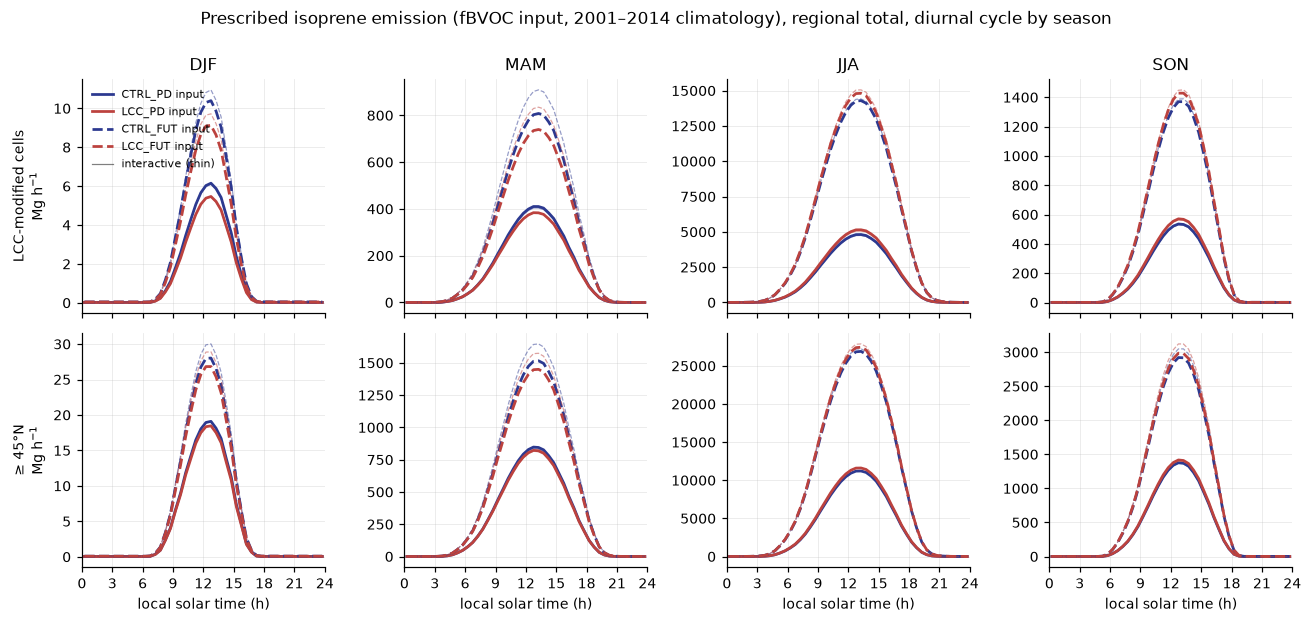

In [5]:
fig, axes = plt.subplots(len(REGIONS), 4, figsize=(12, 5.6), sharex=True)
for i, r in enumerate(REGIONS):
    for j, (s, mo) in enumerate(SEASONS.items()):
        ax = axes[i, j]
        for p in ("PD", "FUT"):
            for v in ("CTRL", "LCC"):
                if (r, v, p) in REG_I:
                    ax.plot(HOURS, season_mean(REG_I[(r, v, p)], mo).mean("year"), color=COL[v], ls=LS[p], lw=0.8, alpha=0.5)
                ax.plot(HOURS, season_mean(REG_E[(r, v, p)], mo), color=COL[v], ls=LS[p], lw=1.8, label=f"{v}_{p} input")
        ax.set_xticks(range(0, 25, 3)); ax.set_xlim(0, 24)
        ax.grid(alpha=0.3, lw=0.5)
        if i == 0: ax.set_title(s)
        if j == 0: ax.set_ylabel(f"{r}\nMg h$^{{-1}}$")
        if i == len(REGIONS) - 1: ax.set_xlabel("local solar time (h)")
axes[0, 0].plot([], [], color="k", lw=0.8, alpha=0.5, label="interactive (thin)")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Prescribed isoprene emission (fBVOC input, 2001–2014 climatology), regional total, diurnal cycle by season", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_fbvoc_diurnal_by_season.png", dpi=200, bbox_inches="tight")

## 4. LCC − CTRL of the prescribed input: absolute and relative

Thick line = input difference (`LCC_P` input − `CTRL_P` input = the emission difference of `LCC_P_fBVOClccP − CTRL_P_fBVOCctrlP`). Shading + thin line = interactive LCC − CTRL, mean ± 95 % t-interval of the paired yearly differences. Relative change only where CTRL exceeds 5 % of its daily peak.

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/numpy/lib/_nanfunctio

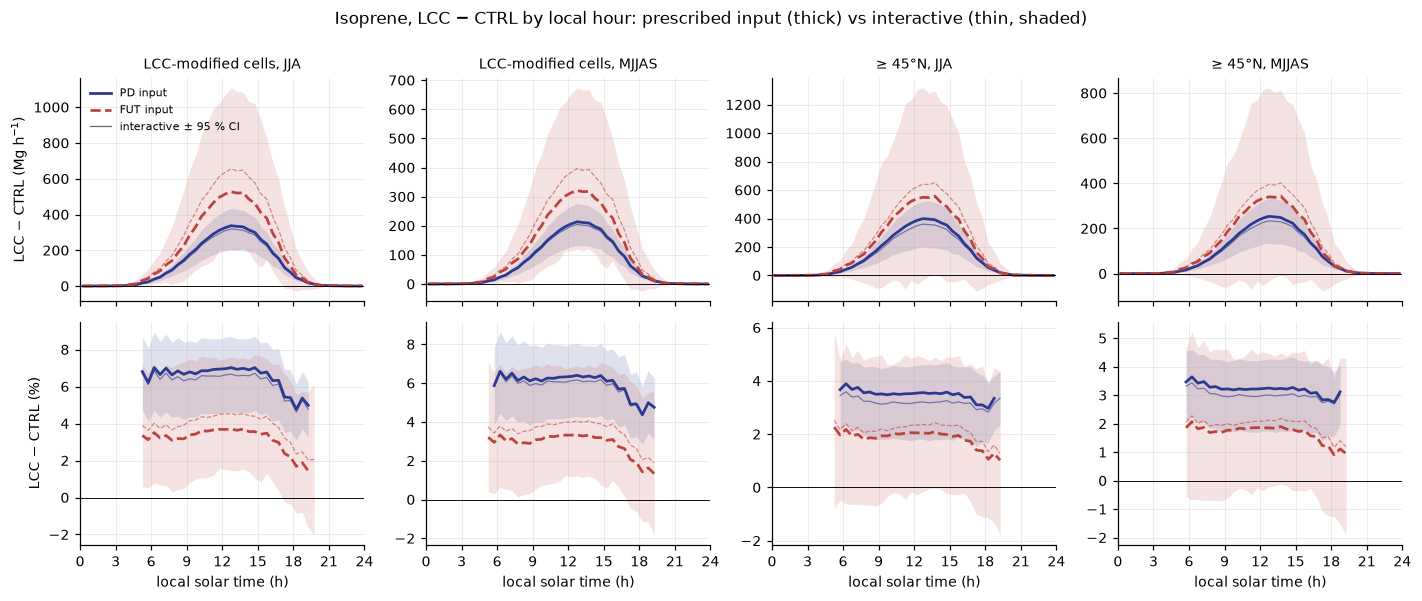

In [6]:
PERIODS_GS = {"JJA": [6, 7, 8], "MJJAS": [5, 6, 7, 8, 9]}

def rel(d, c):
    return (100 * d / c).where(c > 0.05 * c.max())

fig, axes = plt.subplots(2, len(REGIONS) * len(PERIODS_GS), figsize=(13, 5.4), sharex=True)
for i, r in enumerate(REGIONS):
    for k, (s, mo) in enumerate(PERIODS_GS.items()):
        col = i * len(PERIODS_GS) + k
        for p in ("PD", "FUT"):
            c = NAVY if p == "PD" else RED
            ce, le = season_mean(REG_E[(r, "CTRL", p)], mo), season_mean(REG_E[(r, "LCC", p)], mo)
            axes[0, col].plot(HOURS, le - ce, color=c, ls=LS[p], lw=1.8, label=f"{p} input")
            axes[1, col].plot(HOURS, rel(le - ce, ce), color=c, ls=LS[p], lw=1.8)
            if (r, "CTRL", p) in REG_I:
                ci, li = season_mean(REG_I[(r, "CTRL", p)], mo), season_mean(REG_I[(r, "LCC", p)], mo)
                n = ci.sizes["year"]
                for row, d in enumerate([li - ci, (100 * (li - ci) / ci).where(ci.mean("year") > 0.05 * ci.mean("year").max())]):
                    m = d.mean("year")
                    h = d.std("year", ddof=1) / np.sqrt(n) * stats.t.ppf(0.975, n - 1) if n > 1 else m * np.nan
                    axes[row, col].plot(HOURS, m, color=c, ls=LS[p], lw=0.8, alpha=0.6)
                    axes[row, col].fill_between(HOURS, m - h, m + h, color=c, alpha=0.15, lw=0)
        for row in range(2):
            ax = axes[row, col]
            ax.axhline(0, color="k", lw=0.6); ax.grid(alpha=0.3, lw=0.5); ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
        axes[0, col].set_title(f"{r}, {s}", fontsize=9)
        axes[1, col].set_xlabel("local solar time (h)")
axes[0, 0].set_ylabel("LCC − CTRL (Mg h$^{-1}$)")
axes[1, 0].set_ylabel("LCC − CTRL (%)")
axes[0, 0].plot([], [], color="k", lw=0.8, alpha=0.6, label="interactive ± 95 % CI")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Isoprene, LCC − CTRL by local hour: prescribed input (thick) vs interactive (thin, shaded)", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_fbvoc_diurnal_lcc_minus_ctrl.png", dpi=200, bbox_inches="tight")

## 5. Month × local hour, prescribed input (LCC-modified cells)

Top: `CTRL_P` input; bottom: `LCC_P` input − `CTRL_P` input.

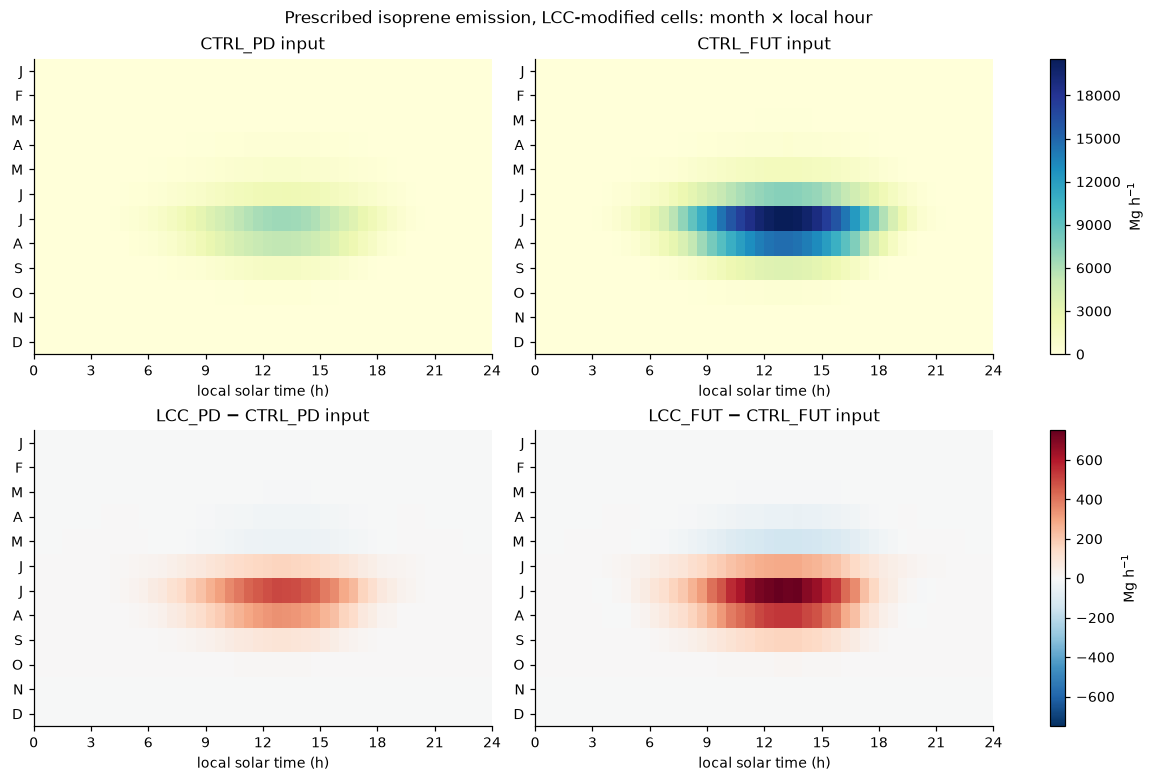

In [7]:
r = "LCC-modified cells"
pers = ["PD", "FUT"]
fig, axes = plt.subplots(2, len(pers), figsize=(5.2 * len(pers), 7.0), squeeze=False, layout="constrained")
months = np.arange(1, 13)
vmax_abs = max(float(REG_E[(r, "CTRL", p)].max()) for p in pers)
dmax = max(float(abs(REG_E[(r, "LCC", p)] - REG_E[(r, "CTRL", p)]).max()) for p in pers)
for j, p in enumerate(pers):
    c = REG_E[(r, "CTRL", p)]
    d = REG_E[(r, "LCC", p)] - c
    im0 = axes[0, j].pcolormesh(np.arange(49) * 0.5, np.arange(0.5, 13.5), c.transpose("month", "lst"),
                                cmap="YlGnBu", vmin=0, vmax=vmax_abs, shading="flat")
    im1 = axes[1, j].pcolormesh(np.arange(49) * 0.5, np.arange(0.5, 13.5), d.transpose("month", "lst"),
                                cmap="RdBu_r", vmin=-dmax, vmax=dmax, shading="flat")
    axes[0, j].set_title(f"CTRL_{p} input"); axes[1, j].set_title(f"LCC_{p} − CTRL_{p} input")
    for ax in axes[:, j]:
        ax.set_yticks(months); ax.set_yticklabels("JFMAMJJASOND"); ax.invert_yaxis()
        ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("local solar time (h)")
fig.colorbar(im0, ax=axes[0, :], label="Mg h$^{-1}$", ticks=MaxNLocator(8))
fig.colorbar(im1, ax=axes[1, :], label="Mg h$^{-1}$", ticks=MaxNLocator(9, symmetric=True))
fig.suptitle(f"Prescribed isoprene emission, {r}: month × local hour")
fig.savefig(OUT / "figures/isoprene_fbvoc_month_by_hour_modified_cells.png", dpi=200, bbox_inches="tight")

## 6. Shape of the cycle by latitude (`CTRL_PD` input, JJA)

Each band normalised by its own daily mean. Thick = prescribed input, thin dotted = interactive `CTRL_PD` (mean over years).

,band,source,peak_lst_h,peak_over_mean,min_over_mean
0,15°S–15°N,prescribed,13.25,3.77,0.0
1,15°S–15°N,interactive,13.25,3.77,0.0
2,45–55°N,prescribed,13.25,3.19,0.0
3,45–55°N,interactive,13.25,3.19,0.0
4,55–65°N,prescribed,13.25,2.98,0.0
5,55–65°N,interactive,13.25,2.97,0.0
6,65–90°N,prescribed,13.25,2.69,0.0
7,65–90°N,interactive,13.25,2.69,0.0


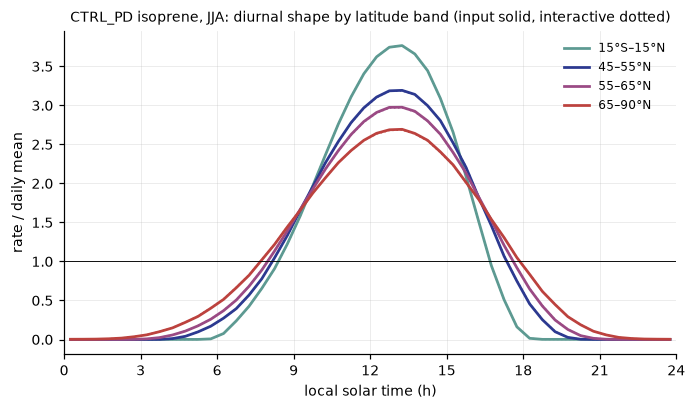

In [8]:
BANDS = {"15°S–15°N": (-15, 15), "45–55°N": (45, 55), "55–65°N": (55, 65), "65–90°N": (65, 90)}
BAND_COL = [TEAL, NAVY, PLUM, RED]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
shape_rows = []
for (b, (lo, hi)), c in zip(BANDS.items(), BAND_COL):
    m = xr.DataArray(np.broadcast_to((lat[:, None] >= lo) & (lat[:, None] < hi), area.shape), coords=area.coords)
    for src, x, kw in [("prescribed", season_mean(regional_total(to_lst(EMS[("CTRL", "PD")]), m), SEASONS["JJA"]), dict(lw=1.8)),
                       ("interactive", season_mean(regional_total(to_lst(INT[("CTRL", "PD")]), m), SEASONS["JJA"]).mean("year"),
                        dict(lw=1.0, ls=":"))]:
        norm = x / x.mean()
        ax.plot(HOURS, norm, color=c, label=b if src == "prescribed" else None, **kw)
        shape_rows.append(dict(band=b, source=src, peak_lst_h=float(HOURS[int(np.argmax(x.values))]),
                               peak_over_mean=float(norm.max()), min_over_mean=float(norm.min())))
ax.axhline(1, color="k", lw=0.6)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.grid(alpha=0.3, lw=0.5)
ax.set_xlabel("local solar time (h)"); ax.set_ylabel("rate / daily mean")
ax.legend(frameon=False, fontsize=8)
ax.set_title("CTRL_PD isoprene, JJA: diurnal shape by latitude band (input solid, interactive dotted)", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_fbvoc_diurnal_shape_by_latitude_JJA.png", dpi=200, bbox_inches="tight")
pd.DataFrame(shape_rows).round(2)

## 7. Summary table

Per region, input and season: mean rate, peak local hour, peak / daily mean, **night share** (18–06 local solar time), for the prescribed input and the interactive reference (mean over years).

In [9]:
night = (HOURS < 6) | (HOURS >= 18)
def stats_row(xm):
    return dict(mean_Mg_per_h=float(xm.mean()), peak_lst_h=float(HOURS[int(np.argmax(xm.values))]),
                peak_over_mean=float(xm.max() / xm.mean()), night_share_pct=float(100 * xm[night].sum() / xm.sum()))
rows = []
for (r, v, p), x in REG_E.items():
    for s, mo in SEASONS.items():
        xe = season_mean(x, mo)
        if float(xe.sum()) == 0:
            continue
        rows.append(dict(region=r, alias=f"{v}_{p}", season=s, source="prescribed", **stats_row(xe)))
        if (r, v, p) in REG_I:
            rows.append(dict(region=r, alias=f"{v}_{p}", season=s, source="interactive",
                             **stats_row(season_mean(REG_I[(r, v, p)], mo).mean("year"))))
summary = pd.DataFrame(rows).round(3)
summary.to_csv(OUT / "tables/isoprene_fbvoc_diurnal_summary.csv", index=False)
summary[summary.season == "JJA"].pivot_table(index=["region", "alias"], columns="source",
                                              values=["mean_Mg_per_h", "peak_lst_h", "peak_over_mean", "night_share_pct"]).round(2)

mean_Mg_per_h            night_share_pct  \
source                        interactive prescribed     interactive   
region             alias                                               
LCC-modified cells CTRL_FUT       5065.01    5008.14            5.12   
                   CTRL_PD        1570.72    1592.74            4.22   
                   LCC_FUT        5275.74    5176.88            5.05   
                   LCC_PD         1672.58    1699.91            4.18   
≥ 45°N             CTRL_FUT       9386.75    9216.21            4.20   
                   CTRL_PD        3617.63    3602.44            3.27   
                   LCC_FUT        9595.13    9393.84            4.18   
                   LCC_PD         3733.14    3728.91            3.27   

                                        peak_lst_h            peak_over_mean  \
source                      prescribed interactive prescribed    interactive   
region             alias                                                       
LCC-modified cells CTRL_FUT       5.06       13.25      13.25           2.84   
                   CTRL_PD        4.19       13.25      13.25           3.02   
                   LCC_FUT        4.99       13.25      13.25           2.85   
                   LCC_PD         4.14       13.25      13.25           3.03   
≥ 45°N             CTRL_FUT       4.12       13.25      13.25           2.90   
                   CTRL_PD        3.24       13.25      13.25           3.11   
                   LCC_FUT        4.10       13.25      13.25           2.91   
                   LCC_PD         3.25       13.25      13.25           3.11   

                                        
source                      prescribed  
region             alias                
LCC-modified cells CTRL_FUT       2.85  
                   CTRL_PD        3.02  
                   LCC_FUT        2.86  
                   LCC_PD         3.03  
≥ 45°N             CTRL_FUT       2.92  
                   CTRL_PD        3.11  
                   LCC_FUT        2.92  
                   LCC_PD         3.12

## 8. fBVOC runs with 30-min output: what the model actually emitted (2001–2002)

`CTRL_PD_fBVOCctrlPD_HR` (teal) prescribes each year's own `CTRL_PD -20261023` emissions; `CTRL_PD_fBVOCctrlPD_C0102` (plum) their 2001–02 climatology; navy = the MEGAN source `CTRL_PD_old`. JJA, mean over 2001–2002. Bottom: run − source in % of the source.

year                                            2001    2002
region             run                                      
LCC-modified cells CTRL_PD_fBVOCctrlPD_C0102  3.9399  3.9399
                   CTRL_PD_fBVOCctrlPD_HR     4.2504  3.6295
                   CTRL_PD_old                4.2524  3.6312
≥ 45°N             CTRL_PD_fBVOCctrlPD_C0102  8.7553  8.7553
                   CTRL_PD_fBVOCctrlPD_HR     9.3825  8.1281
                   CTRL_PD_old                9.3869  8.1320

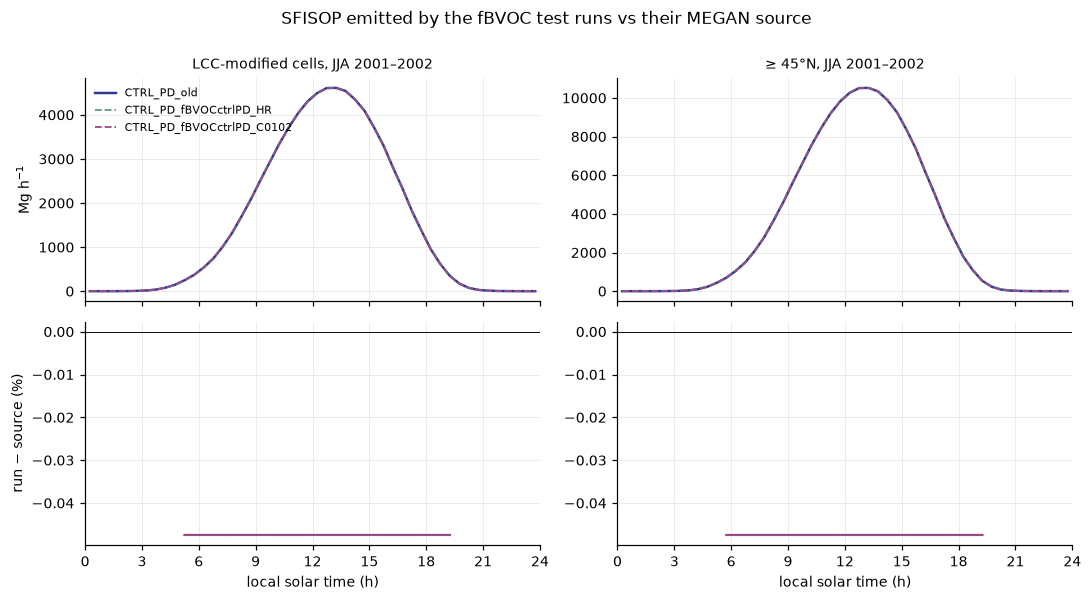

In [10]:
rows = []
for (r, a), x in REG_T.items():
    for y in x.year.values:
        rows.append(dict(region=r, run=a, year=int(y), isoprene_Tg_per_yr=float(annual(x.sel(year=y)))))
tt = pd.DataFrame(rows).pivot_table(index=["region", "run"], columns="year", values="isoprene_Tg_per_yr")
tt.round(4).to_csv(OUT / "tables/annual_isoprene_totals_fbvoc_test_runs_Tg.csv")
display(tt.round(4))

fig, axes = plt.subplots(2, len(REGIONS), figsize=(10, 5.4), sharex=True)
for i, r in enumerate(REGIONS):
    src = season_mean(REG_T[(r, "CTRL_PD_old")], SEASONS["JJA"]).mean("year")
    for a, c in TESTS.items():
        x = season_mean(REG_T[(r, a)], SEASONS["JJA"]).mean("year")
        axes[0, i].plot(HOURS, x, color=c, lw=1.6 if a == "CTRL_PD_old" else 1.2, ls="-" if a == "CTRL_PD_old" else "--", label=a)
        if a != "CTRL_PD_old":
            axes[1, i].plot(HOURS, rel(x - src, src), color=c, lw=1.4)
    axes[0, i].set_title(f"{r}, JJA 2001–2002", fontsize=9)
    axes[1, i].axhline(0, color="k", lw=0.6)
    for ax in axes[:, i]:
        ax.grid(alpha=0.3, lw=0.5); ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
    axes[1, i].set_xlabel("local solar time (h)")
axes[0, 0].set_ylabel("Mg h$^{-1}$"); axes[1, 0].set_ylabel("run − source (%)")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("SFISOP emitted by the fBVOC test runs vs their MEGAN source", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_fbvoc_test_runs_diurnal_JJA.png", dpi=200, bbox_inches="tight")

## 9. Full time series at hourly resolution

Regional total, hourly = mean of the two 30-min steps, **UTC**. Every year written by the reducer is shown (FUT years appear when FUT batch 2 is reduced; rerun the reducer, then this notebook). The prescribed input is one cyclic year, drawn on a 2001 calendar.

In [11]:
REG_NAMES = list(REGIONS)

def load_ts(name):
    # (region, 8760) hourly Mg h-1 + hour-centre datetimes; noleap file, so leap years are refused
    ds = load_nc(TS_DIR / f"ts_{name}.nc", decode_times=False)
    assert list(ds.region.values) == ["LCC-modified cells", ">= 45N"]
    y = int(ds.time.values[0] // 365) + 2000 if "ems" not in name else 2001
    assert y % 4 != 0, "leap year: noleap → calendar mapping needed"
    h = ds.SFISOP.values.reshape(2, 8760, 2).mean(-1)
    t = pd.date_range(f"{y}-01-01 00:30", periods=8760, freq="h")
    return t, h

TS_I = {}
for f in sorted(TS_DIR.glob("ts_*_*.nc")):
    m = re.fullmatch(r"ts_(CTRL|LCC)_(PD|FUT)_(\d{4})\.nc", f.name)
    if m:
        TS_I[(m[1], m[2], int(m[3]))] = load_ts(f.stem.removeprefix("ts_"))
TS_E = {(v, p): load_ts(f"ems_{v}_{p}") for v in ("CTRL", "LCC") for p in ("PD", "FUT")}
TS_T = {a: [load_ts(f"{a}_{y}") for y in (2001, 2002)] for a in TESTS}
TS_YEARS = {p: sorted({y for (v, q, y) in TS_I if q == p and v == "CTRL"} & {y for (v, q, y) in TS_I if q == p and v == "LCC"})
            for p in ("PD", "FUT")}
print("time-series years:", TS_YEARS)

def fmt_year(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.grid(alpha=0.3, lw=0.5)

time-series years: {'PD': [2001, 2002, 2005, 2006, 2010, 2011], 'FUT': [2001, 2005, 2010]}


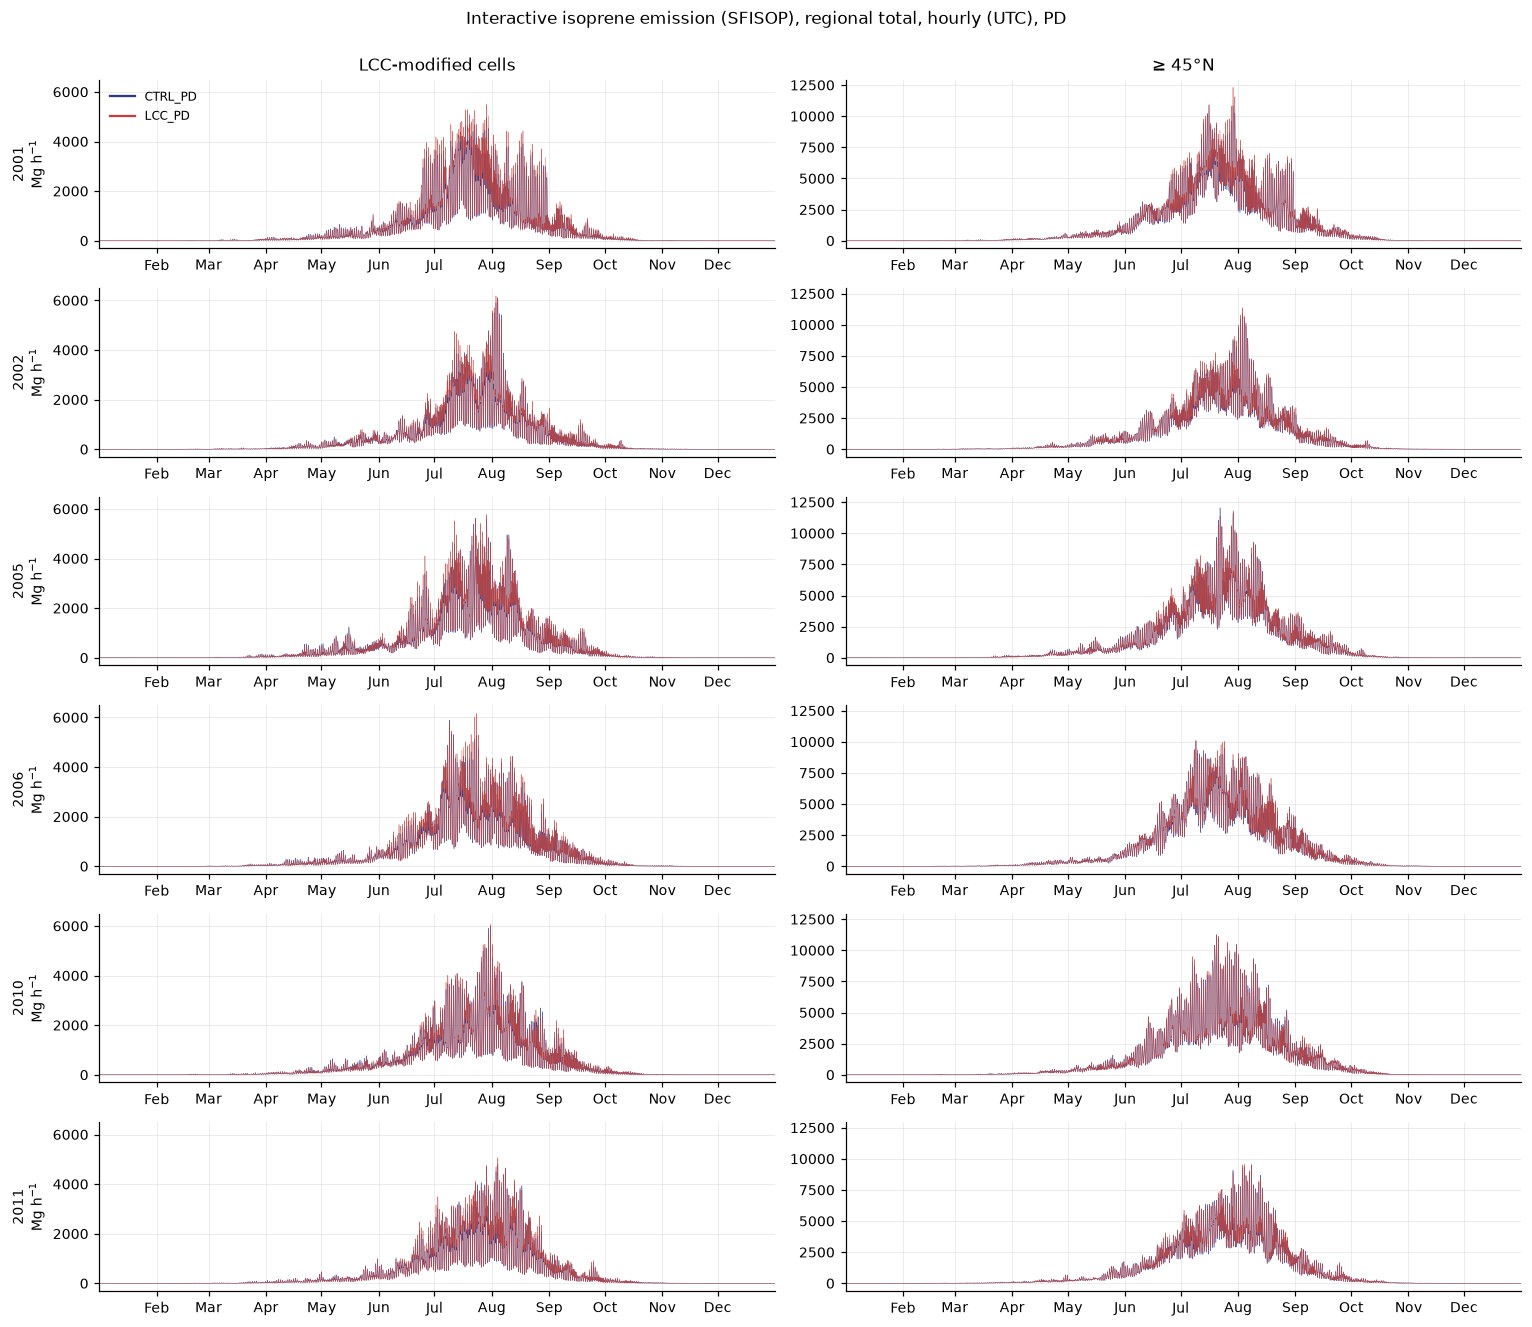

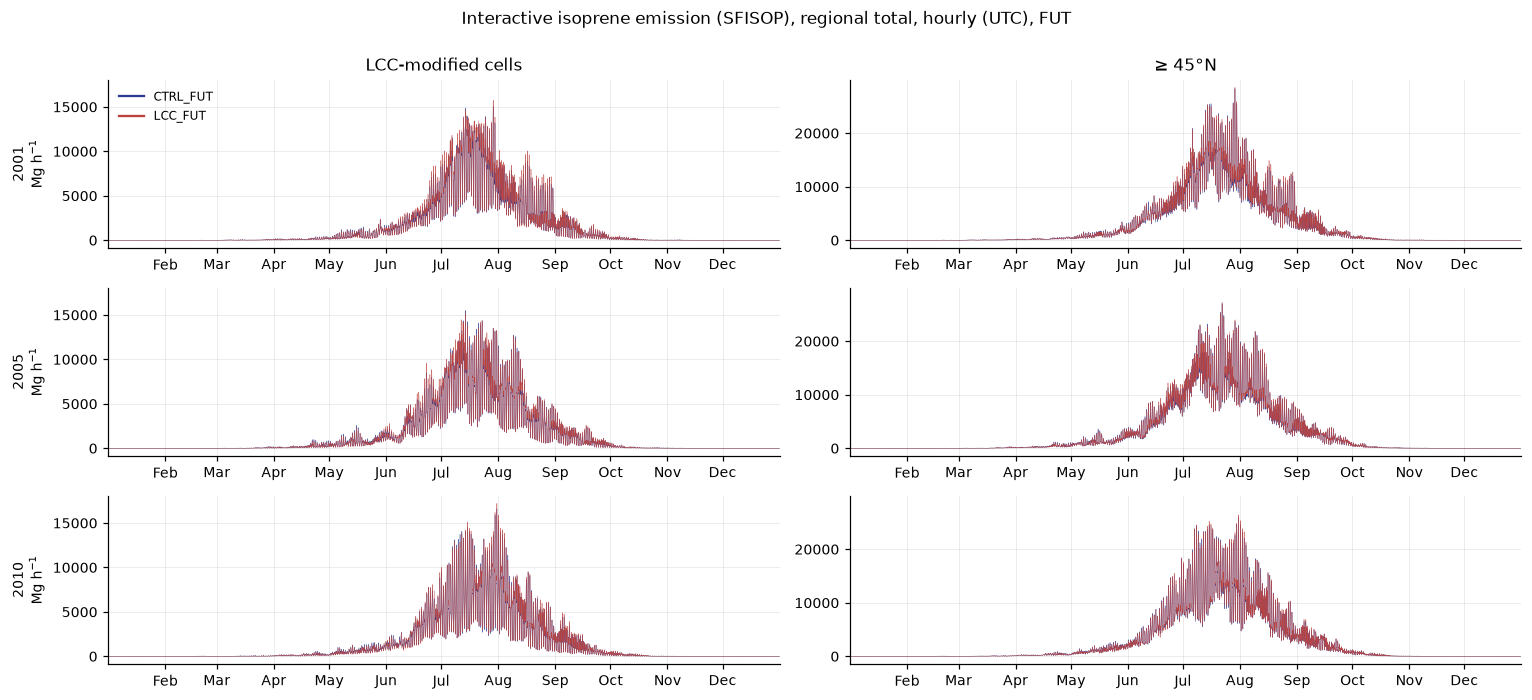

In [12]:
# 9a. interactive MEGAN, every year, CTRL and LCC
for p in ("PD", "FUT"):
    ys = TS_YEARS[p]
    if not ys:
        continue
    fig, axes = plt.subplots(len(ys), 2, figsize=(14, 1.9 * len(ys) + 0.6), squeeze=False, sharey="col")
    for i, y in enumerate(ys):
        for j, r in enumerate(REG_NAMES):
            ax = axes[i, j]
            for v in ("CTRL", "LCC"):
                t, h = TS_I[(v, p, y)]
                ax.plot(t, h[j], color=COL[v], lw=0.25, label=f"{v}_{p}")
            fmt_year(ax)
            ax.set_xlim(t[0], t[-1])
            if i == 0: ax.set_title(r)
            if j == 0: ax.set_ylabel(f"{y}\nMg h$^{{-1}}$")
    leg = axes[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
    for l in leg.get_lines(): l.set_linewidth(1.5)
    fig.suptitle(f"Interactive isoprene emission (SFISOP), regional total, hourly (UTC), {p}", y=1.0)
    fig.tight_layout()
    fig.savefig(OUT / f"figures/isoprene_timeseries_hourly_interactive_{p}.png", dpi=200, bbox_inches="tight")

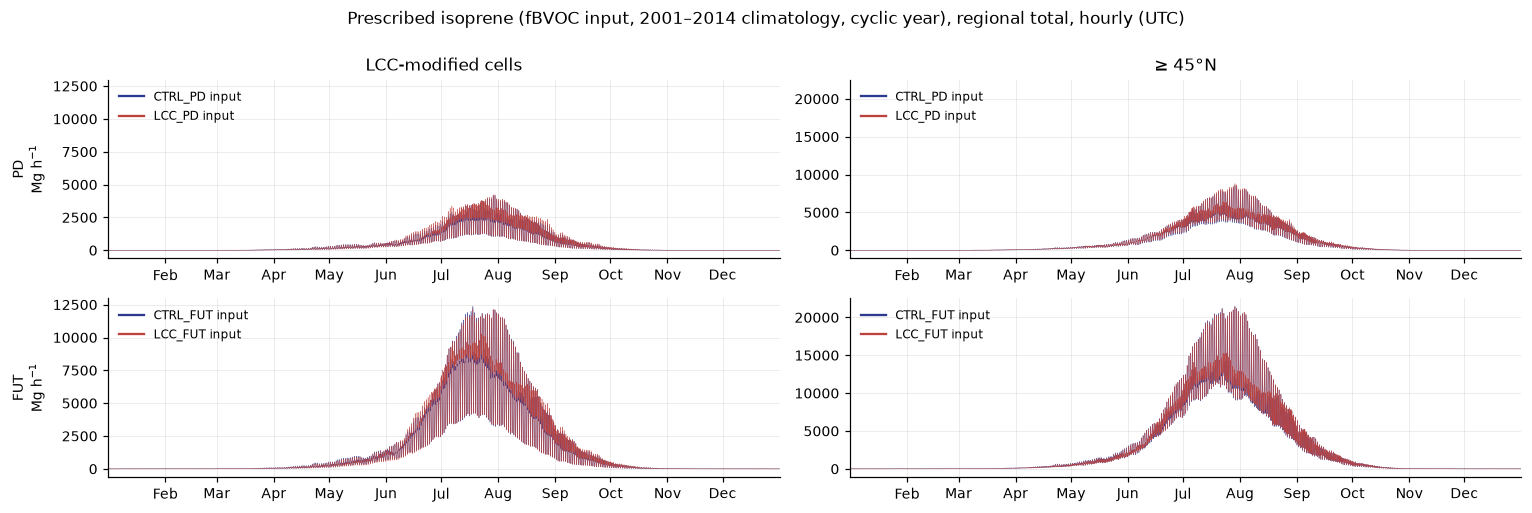

In [13]:
# 9b. prescribed input (cyclic year)
fig, axes = plt.subplots(2, 2, figsize=(14, 4.6), sharey="col")
for i, p in enumerate(("PD", "FUT")):
    for j, r in enumerate(REG_NAMES):
        ax = axes[i, j]
        for v in ("CTRL", "LCC"):
            t, h = TS_E[(v, p)]
            ax.plot(t, h[j], color=COL[v], lw=0.25, label=f"{v}_{p} input")
        fmt_year(ax); ax.set_xlim(t[0], t[-1])
        if i == 0: ax.set_title(r)
        if j == 0: ax.set_ylabel(f"{p}\nMg h$^{{-1}}$")
        leg = ax.legend(frameon=False, fontsize=8, loc="upper left")
        for l in leg.get_lines(): l.set_linewidth(1.5)
fig.suptitle("Prescribed isoprene (fBVOC input, 2001–2014 climatology, cyclic year), regional total, hourly (UTC)", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_timeseries_hourly_prescribed_input.png", dpi=200, bbox_inches="tight")

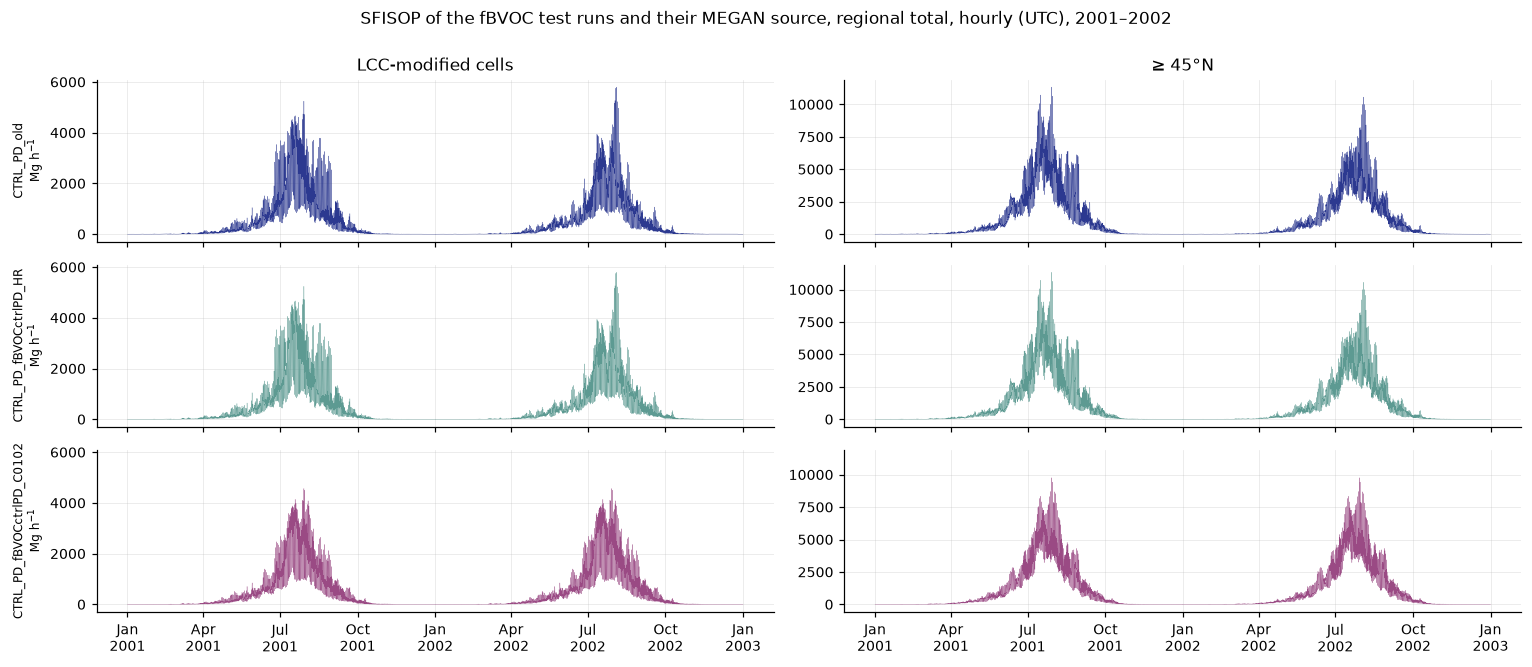

In [14]:
# 9c. fBVOC test runs, 2001-2002 continuous, one row per run
fig, axes = plt.subplots(len(TESTS), 2, figsize=(14, 6.0), sharex=True, sharey="col")
for i, (a, c) in enumerate(TESTS.items()):
    for j, r in enumerate(REG_NAMES):
        ax = axes[i, j]
        for t, h in TS_T[a]:
            ax.plot(t, h[j], color=c, lw=0.2)
        ax.xaxis.set_major_locator(mdates.MonthLocator((1, 4, 7, 10)))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
        ax.grid(alpha=0.3, lw=0.5)
        if i == 0: ax.set_title(r)
        if j == 0: ax.set_ylabel(f"{a}\nMg h$^{{-1}}$", fontsize=8)
fig.suptitle("SFISOP of the fBVOC test runs and their MEGAN source, regional total, hourly (UTC), 2001–2002", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_timeseries_hourly_fbvoc_test_runs.png", dpi=200, bbox_inches="tight")

### 9d. Zoom: two weeks of July, hourly (LCC-modified cells)

Interactive (solid, one year) against the prescribed input of the same alias (dashed, climatology): the input keeps the diurnal cycle but loses most of the day-to-day weather signal.

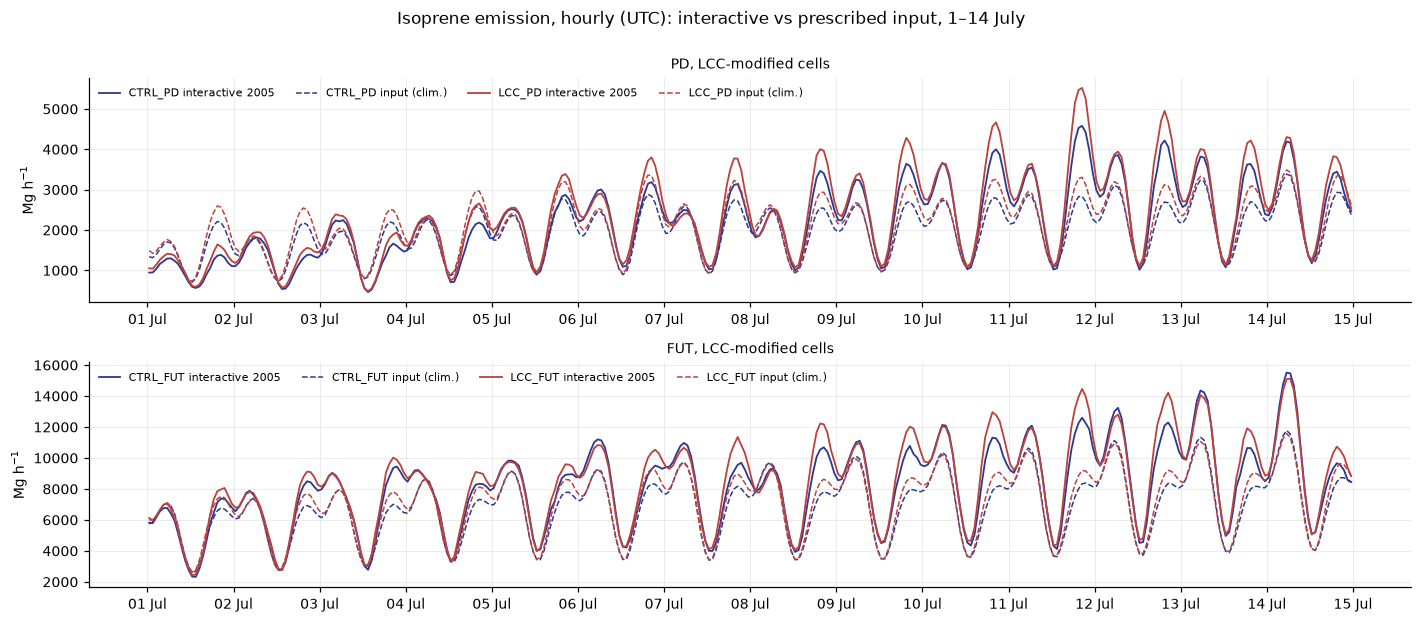

In [15]:
ZOOM_DAYS = ("07-01", "07-15")
fig, axes = plt.subplots(2, 1, figsize=(13, 5.6))
for ax, p in zip(axes, ("PD", "FUT")):
    if not TS_YEARS[p]:
        continue
    y = 2005 if 2005 in TS_YEARS[p] else TS_YEARS[p][0]
    for v in ("CTRL", "LCC"):
        t, h = TS_I[(v, p, y)]
        s = (t >= f"{y}-{ZOOM_DAYS[0]}") & (t < f"{y}-{ZOOM_DAYS[1]}")
        ax.plot(t[s], h[0, s], color=COL[v], lw=1.2, label=f"{v}_{p} interactive {y}")
        te, he = TS_E[(v, p)]
        se = (te >= f"2001-{ZOOM_DAYS[0]}") & (te < f"2001-{ZOOM_DAYS[1]}")
        ax.plot(t[s], he[0, se], color=COL[v], lw=1.0, ls="--", label=f"{v}_{p} input (clim.)")
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.grid(alpha=0.3, lw=0.5); ax.set_ylabel("Mg h$^{-1}$")
    ax.legend(frameon=False, fontsize=7, ncol=4, loc="upper left")
    ax.set_title(f"{p}, LCC-modified cells", fontsize=9)
fig.suptitle("Isoprene emission, hourly (UTC): interactive vs prescribed input, 1–14 July", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_timeseries_hourly_zoom_july.png", dpi=200, bbox_inches="tight")

## 10. Each production fBVOC run against its own interactive source

Sections 3–7 compare the prescribed input with the MEGAN exact-split runs (another chain, other years). Here each production fBVOC run is compared with **the run its emissions come from**, over **the years the input averages** (2001–2014), and month by month over 2001–2025.

| fBVOC run | Source (interactive) | Source 30-min h1, 2001–2014 |
|---|---|---|
| `CTRL_PD_fBVOCctrlPD`, `LCC_PD_fBVOCctrlPD`, `LCC_FUT_fBVOCctrlPD` | `CTRL_PD` `-20261029` | own h1 |
| `LCC_PD_fBVOClccPD`, `LCC_FUT_fBVOClccPD` | `LCC_PD` `-20261028` | own h1 |
| `CTRL_FUT_fBVOCctrlFUT`, `LCC_FUT_fBVOCctrlFUT` | `CTRL_FUT` `-20261028` | own h1 |
| `LCC_FUT_fBVOClccFUT` | `LCC_FUT` `-20261028` | output-only rerun `LCC_FUT_HRBVOC` s1–s3 |

**What can be compared.** The fBVOC runs write `SFISOP` only monthly (h0). Their sub-daily flux is the input file (checked on the replay test, section 8; checked again below at monthly resolution for every run and year). So:
- **diurnal / hourly**: source h1, every year 2001–2014 (`fbvoc/diurnal_src_<SRC>_<YEAR>.nc`, `timeseries/ts_src_<SRC>_<YEAR>.nc`) against the input (= what every run using it emits);
- **monthly**: run h0 against source h0, every year 2001–2025 (`timeseries/monthly_h0_SFISOP_fbvoc_vs_source.csv`).

All from `reduce_isoprene_fbvoc_vs_source.py` (this folder). Run and source share the nudged weather, so the year-to-year and hour-to-hour departures of the source from the input are exactly the emission signal the fBVOC run lacks.

In [16]:
PAIRS = {"CTRL_PD_fBVOCctrlPD": "CTRL_PD", "LCC_PD_fBVOCctrlPD": "CTRL_PD", "LCC_FUT_fBVOCctrlPD": "CTRL_PD",
         "LCC_PD_fBVOClccPD": "LCC_PD", "LCC_FUT_fBVOClccPD": "LCC_PD",
         "CTRL_FUT_fBVOCctrlFUT": "CTRL_FUT", "LCC_FUT_fBVOCctrlFUT": "CTRL_FUT", "LCC_FUT_fBVOClccFUT": "LCC_FUT"}
SOURCES = ["CTRL_PD", "LCC_PD", "CTRL_FUT", "LCC_FUT"]
SRC_YEARS = list(range(2001, 2015))
ems_of = lambda s: EMS[tuple(s.split("_"))]

SRC, SRC_CASE = {}, {}
for s in SOURCES:
    dss = [load_nc(FB_DIR / f"diurnal_src_{s}_{y}.nc") for y in SRC_YEARS]
    SRC[s] = xr.concat([d.SFISOP.expand_dims(year=[y]) for d, y in zip(dss, SRC_YEARS)], "year")
    assert np.allclose(SRC[s].lat, lat) and np.allclose(SRC[s].lon, lon)
    print(f"source {s}: {sorted({d.attrs['case'] for d in dss})}")
REG_S = {(r, s): regional_total(to_lst(x), m) for r, m in REGIONS.items() for s, x in SRC.items()}

H0 = pd.read_csv(TS_DIR / "monthly_h0_SFISOP_fbvoc_vs_source.csv")
H0["region"] = H0.region.replace({">= 45N": "≥ 45°N"})
H0["Tg"] = H0.Mg_per_h * 24 * DAYS[H0.month - 1] / 1e6          # monthly emission, Tg
print(H0.groupby(["role", "alias"]).year.agg(["min", "max", "count"]))

source CTRL_PD: ['NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029']
source LCC_PD: ['NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028']
source CTRL_FUT: ['NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028']
source LCC_FUT: ['NF2100ssp585norbc_tropstratchem_nudg_lcc_HRBVOC_f19_f19-20261104-s1', 'NF2100ssp585norbc_tropstratchem_nudg_lcc_HRBVOC_f19_f19-20261104-s2', 'NF2100ssp585norbc_tropstratchem_nudg_lcc_HRBVOC_f19_f19-20261104-s3']
                                        min   max  count
role            alias                                   
fBVOC           CTRL_FUT_fBVOCctrlFUT  2001  2025    600
                CTRL_PD_fBVOCctrlPD    2001  2025    600
                LCC_FUT_fBVOCctrlFUT   2001  2025    600
                LCC_FUT_fBVOCctrlPD    2001  2025    600
                LCC_FUT_fBVOClccFUT    2001  2025    600
                LCC_FUT_fBVOClccPD     2001  2025    600
                LCC_PD_fBVOCctrlPD     2001  2025    600
                LCC_PD_fBVOClccPD

### 10.1 Checks

1. **Input = source mean over 2001–2014**, grid cell by grid cell (monthly diurnal composites), and as regional annual totals.
2. **Each fBVOC run emits the input in every month of every year**: run h0 monthly mean against the monthly mean of the input composite.
3. **`LCC_FUT` h0 = `LCC_FUT_HRBVOC` h0** (the output-only rerun the `LCC_FUT` input was built from).

In [17]:
rows = []
for s in SOURCES:
    e, m = ems_of(s), SRC[s].mean("year")
    rows.append(dict(source=s, max_abs_diff_over_max=float(abs(m - e).max() / e.max()),
                     **{f"{r}: input / source mean (annual)": float(annual(REG_E[(r, *s.split('_'))]) / annual(REG_S[(r, s)]).mean())
                        for r in REGIONS}))
display(pd.DataFrame(rows).set_index("source").style.format("{:.2e}", subset=["max_abs_diff_over_max"]).format("{:.5f}", subset=[c for c in rows[0] if c.startswith(("LCC", "≥"))]))

# 2. every run, every month: h0 / input monthly mean
inp = {(r, s): REG_E[(r, *s.split("_"))].mean("lst").to_series() for r in REGIONS for s in SOURCES}
chk = []
for run, s in PAIRS.items():
    for r in REGIONS:
        h = H0[(H0.alias == run) & (H0.region == r)]
        ratio = h.Mg_per_h.values / inp[(r, s)].loc[h.month].values
        chk.append(dict(run=run, source=s, region=r, months=len(h), years=f"{h.year.min()}–{h.year.max()}",
                        max_abs_dev_pct=100 * np.abs(ratio - 1).max(), mean_dev_pct=100 * (ratio.mean() - 1)))
chk = pd.DataFrame(chk)
display(chk.round(4))

# 3. LCC_FUT vs its h1 rerun
a = H0[(H0.alias == "LCC_FUT")].set_index(["region", "year", "month"]).Mg_per_h
b = H0[H0.alias.str.startswith("LCC_FUT_HRBVOC")].set_index(["region", "year", "month"]).Mg_per_h
print(f"LCC_FUT h0 vs LCC_FUT_HRBVOC h0, {b.size} region-months: max |rel diff| = {float((b / a.loc[b.index] - 1).abs().max()):.2e}")

,max_abs_diff_over_max,LCC-modified cells: input / source mean (annual),≥ 45°N: input / source mean (annual)
source,,,
CTRL_PD,4.61e-04,1.00000,1.00000
LCC_PD,5.30e-04,1.00000,1.00000
CTRL_FUT,3.69e-04,1.00000,1.00000
LCC_FUT,3.52e-04,1.00000,1.00000


,run,source,region,months,years,max_abs_dev_pct,mean_dev_pct
0,CTRL_PD_fBVOCctrlPD,CTRL_PD,LCC-modified cells,300,2001–2025,0.0476,-0.0474
1,CTRL_PD_fBVOCctrlPD,CTRL_PD,≥ 45°N,300,2001–2025,0.0476,-0.0475
2,LCC_PD_fBVOCctrlPD,CTRL_PD,LCC-modified cells,300,2001–2025,0.0476,-0.0474
3,LCC_PD_fBVOCctrlPD,CTRL_PD,≥ 45°N,300,2001–2025,0.0476,-0.0475
4,LCC_FUT_fBVOCctrlPD,CTRL_PD,LCC-modified cells,300,2001–2025,0.0476,-0.0474
5,LCC_FUT_fBVOCctrlPD,CTRL_PD,≥ 45°N,300,2001–2025,0.0476,-0.0475
6,LCC_PD_fBVOClccPD,LCC_PD,LCC-modified cells,300,2001–2025,0.0476,-0.0474
7,LCC_PD_fBVOClccPD,LCC_PD,≥ 45°N,300,2001–2025,0.0478,-0.0474
8,LCC_FUT_fBVOClccPD,LCC_PD,LCC-modified cells,300,2001–2025,0.0476,-0.0474
9,LCC_FUT_fBVOClccPD,LCC_PD,≥ 45°N,300,2001–2025,0.0478,-0.0474


LCC_FUT h0 vs LCC_FUT_HRBVOC h0, 336 region-months: max |rel diff| = 0.00e+00


### 10.2 Diurnal cycle: each source year against the input (JJA)

Thin grey = each source year 2001–2014; navy = source mean; teal dashed = input = what every fBVOC run using that source emits. Bottom row of each region: (source year − input) / input, by local hour (where the input exceeds 5 % of its peak).

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/xarray/core/dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax wi

,region,source,season,input_Mg_per_h,year_dev_sd_pct,year_dev_min_pct,year_dev_max_pct,peak_lst_input,peak_lst_years,night_share_input_pct,night_share_years_pct
2,LCC-modified cells,CTRL_PD,JJA,1592.74,8.19,-15.28,14.67,13.25,12.75–13.25,4.19,4.0–4.5
6,LCC-modified cells,LCC_PD,JJA,1699.91,8.73,-15.89,14.69,13.25,12.75–13.25,4.14,4.0–4.5
10,LCC-modified cells,CTRL_FUT,JJA,5008.14,7.07,-12.04,14.98,13.25,13.25–13.25,5.06,4.9–5.4
14,LCC-modified cells,LCC_FUT,JJA,5176.88,7.01,-13.26,13.62,13.25,12.75–13.25,4.99,4.8–5.3
18,≥ 45°N,CTRL_PD,JJA,3602.44,6.19,-11.35,10.72,13.25,12.75–13.25,3.24,3.1–3.4
22,≥ 45°N,LCC_PD,JJA,3728.91,6.28,-11.25,10.66,13.25,12.75–13.25,3.25,3.1–3.4
26,≥ 45°N,CTRL_FUT,JJA,9216.21,5.58,-12.25,9.21,13.25,13.25–13.25,4.12,4.0–4.3
30,≥ 45°N,LCC_FUT,JJA,9393.84,5.43,-12.20,8.31,13.25,13.25–13.25,4.10,4.0–4.3


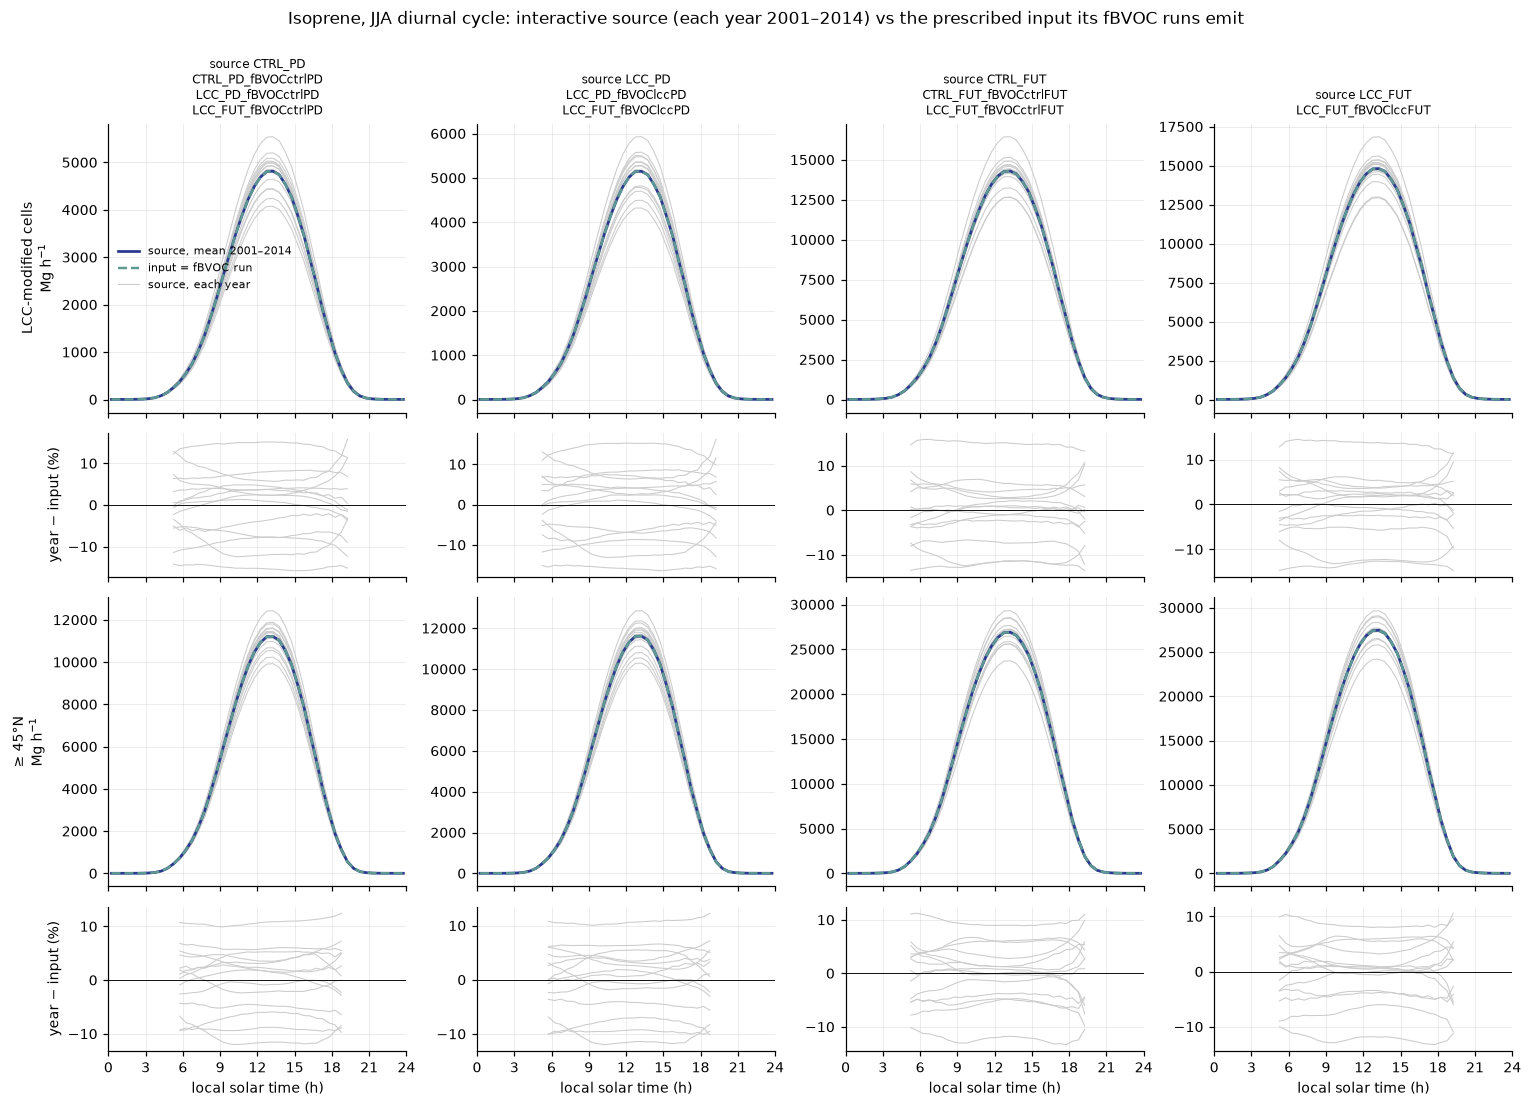

In [18]:
USERS = {s: [a for a, q in PAIRS.items() if q == s] for s in SOURCES}
fig, axes = plt.subplots(2 * len(REGIONS), len(SOURCES), figsize=(14, 10), sharex=True,
                         gridspec_kw=dict(height_ratios=[2, 1] * len(REGIONS)))
for i, r in enumerate(REGIONS):
    for j, s in enumerate(SOURCES):
        ax, axd = axes[2 * i, j], axes[2 * i + 1, j]
        e = season_mean(REG_E[(r, *s.split("_"))], SEASONS["JJA"])
        x = season_mean(REG_S[(r, s)], SEASONS["JJA"])
        for y in SRC_YEARS:
            ax.plot(HOURS, x.sel(year=y), color=LGREY, lw=0.7)
            axd.plot(HOURS, rel(x.sel(year=y) - e, e), color=LGREY, lw=0.7)
        ax.plot(HOURS, x.mean("year"), color=NAVY, lw=1.8, label="source, mean 2001–2014")
        ax.plot(HOURS, e, color=TEAL, lw=1.6, ls="--", label="input = fBVOC run")
        lo, hi = rel(x - e, e).min("year"), rel(x - e, e).max("year")
        axd.axhline(0, color="k", lw=0.6)
        for a_ in (ax, axd):
            a_.grid(alpha=0.3, lw=0.5); a_.set_xlim(0, 24); a_.set_xticks(range(0, 25, 3))
        if i == 0:
            ax.set_title(f"source {s}\n" + "\n".join(USERS[s]), fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{r}\nMg h$^{{-1}}$"); axd.set_ylabel("year − input (%)")
        if i == len(REGIONS) - 1:
            axd.set_xlabel("local solar time (h)")
axes[0, 0].plot([], [], color=LGREY, lw=0.7, label="source, each year")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Isoprene, JJA diurnal cycle: interactive source (each year 2001–2014) vs the prescribed input its fBVOC runs emit", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_fbvoc_vs_source_diurnal_JJA.png", dpi=200, bbox_inches="tight")

# per source, region, season: spread of the source years around the input
rows = []
for r in REGIONS:
    for s in SOURCES:
        for sn, mo in SEASONS.items():
            e = season_mean(REG_E[(r, *s.split("_"))], mo)
            if float(e.sum()) == 0:
                continue
            x = season_mean(REG_S[(r, s)], mo)
            dm = 100 * (x.mean("lst") / e.mean() - 1)                 # daily-mean departure per year
            pk = HOURS[x.argmax("lst").values]
            rows.append(dict(region=r, source=s, season=sn, input_Mg_per_h=float(e.mean()),
                             year_dev_sd_pct=float(dm.std(ddof=1)), year_dev_min_pct=float(dm.min()), year_dev_max_pct=float(dm.max()),
                             peak_lst_input=float(HOURS[int(e.argmax())]), peak_lst_years=f"{pk.min():.2f}–{pk.max():.2f}",
                             night_share_input_pct=float(100 * e[night].sum() / e.sum()),
                             night_share_years_pct=f"{float(100 * (x[:, night].sum('lst') / x.sum('lst')).min()):.1f}–{float(100 * (x[:, night].sum('lst') / x.sum('lst')).max()):.1f}"))
spread = pd.DataFrame(rows).round(2)
spread.to_csv(OUT / "tables/isoprene_fbvoc_vs_source_diurnal_spread.csv", index=False)
spread[spread.season == "JJA"]

### 10.3 Monthly emission, every year 2001–2025: each fBVOC run against its source (h0)

One panel per source (own y axis per row); navy = source, teal = its fBVOC runs (all on top of each other if they emit the same input). The input averages 2001–2014 (shaded); 2015–2025 repeat the same cycle while the source follows the nudged 2015–2025 weather.

Table: run and source means; run / source **ratio of the means** (2001–2014: the input period; 2015–2025: the extension, where the runs repeat the 2001–2014 cycle); per-year range of run / source; interannual SD.

,run,source,region,run_mean_Tg,source_mean_0114_Tg,source_mean_1525_Tg,run_over_source_mean_0114_pct,run_over_source_mean_1525_pct,yearly_dev_range_pct,source_iav_sd_pct,run_iav_sd_pct
0,CTRL_PD_fBVOCctrlPD,CTRL_PD,LCC-modified cells,4.124,4.126,4.035,-0.047,2.202,-17.6 to 14.8,8.228,0.0
1,CTRL_PD_fBVOCctrlPD,CTRL_PD,≥ 45°N,9.354,9.359,9.147,-0.048,2.261,-13.4 to 18.0,6.657,0.0
2,LCC_PD_fBVOCctrlPD,CTRL_PD,LCC-modified cells,4.124,4.126,4.035,-0.047,2.202,-17.6 to 14.8,8.228,0.0
3,LCC_PD_fBVOCctrlPD,CTRL_PD,≥ 45°N,9.354,9.359,9.147,-0.048,2.261,-13.4 to 18.0,6.657,0.0
4,LCC_FUT_fBVOCctrlPD,CTRL_PD,LCC-modified cells,4.124,4.126,4.035,-0.047,2.202,-17.6 to 14.8,8.228,0.0
5,LCC_FUT_fBVOCctrlPD,CTRL_PD,≥ 45°N,9.354,9.359,9.147,-0.048,2.261,-13.4 to 18.0,6.657,0.0
6,LCC_PD_fBVOClccPD,LCC_PD,LCC-modified cells,4.365,4.367,4.283,-0.047,1.896,-17.3 to 15.5,8.251,0.0
7,LCC_PD_fBVOClccPD,LCC_PD,≥ 45°N,9.641,9.645,9.424,-0.047,2.296,-12.8 to 17.5,6.513,0.0
8,LCC_FUT_fBVOClccPD,LCC_PD,LCC-modified cells,4.365,4.367,4.283,-0.047,1.896,-17.3 to 15.5,8.251,0.0
9,LCC_FUT_fBVOClccPD,LCC_PD,≥ 45°N,9.641,9.645,9.424,-0.047,2.296,-12.8 to 17.5,6.513,0.0


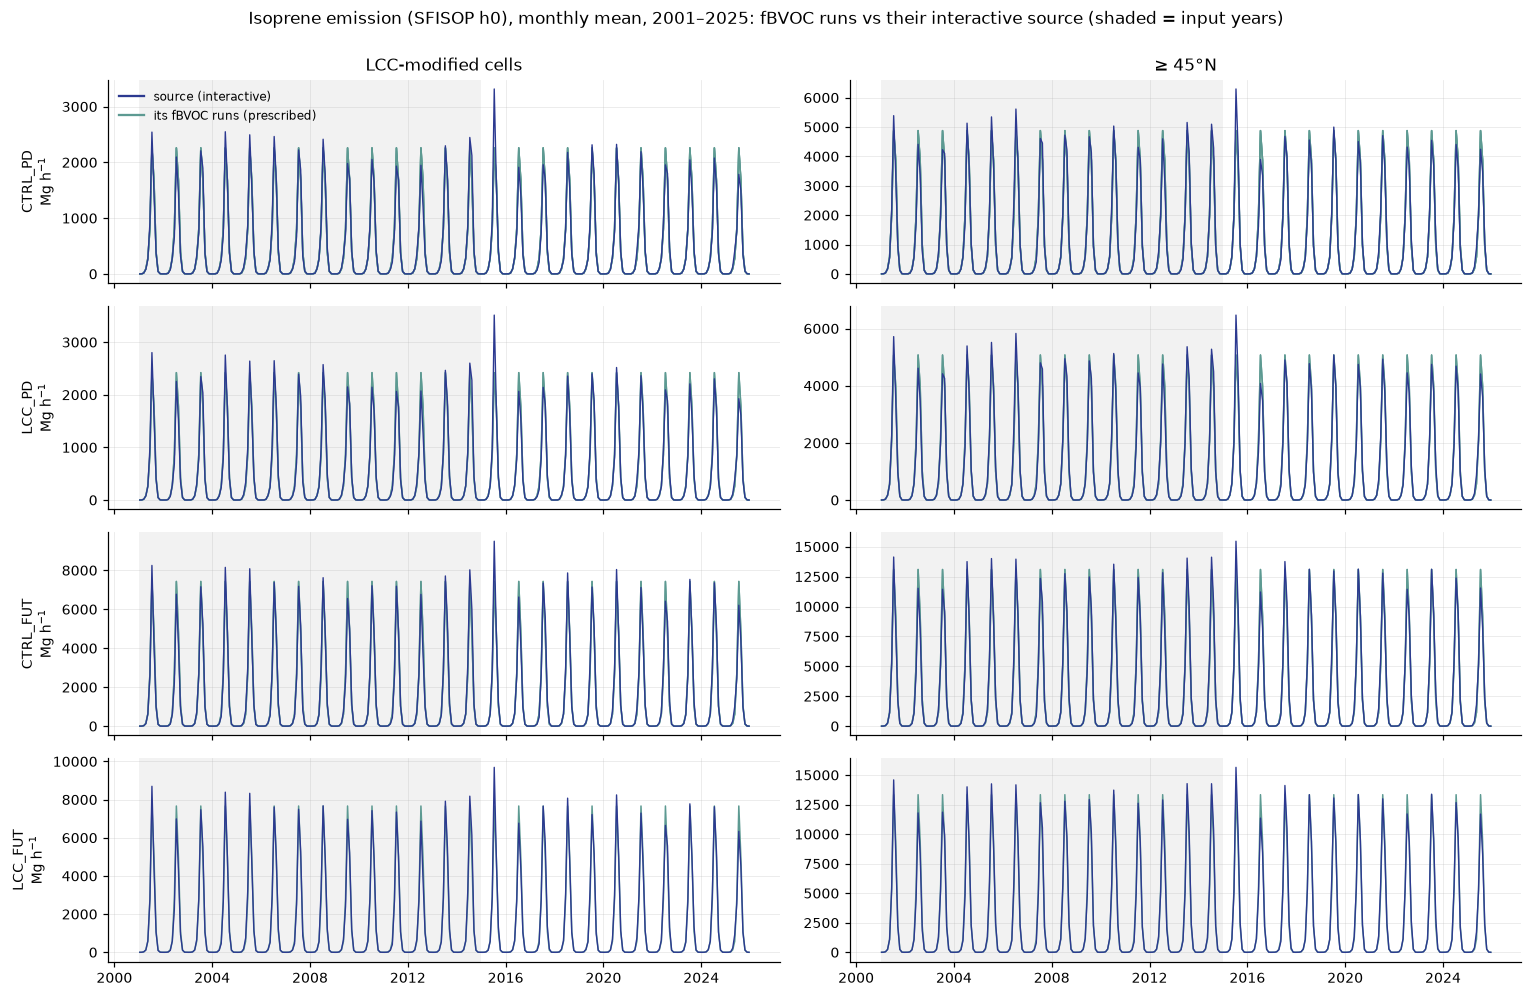

In [19]:
fig, axes = plt.subplots(len(SOURCES), len(REGIONS), figsize=(14, 9), sharex=True)
for i, s in enumerate(SOURCES):
    for j, r in enumerate(REGIONS):
        ax = axes[i, j]
        src = H0[(H0.alias == s) & (H0.region == r)].sort_values(["year", "month"])
        t = pd.to_datetime(dict(year=src.year, month=src.month, day=15))
        ax.axvspan(pd.Timestamp("2001-01-01"), pd.Timestamp("2015-01-01"), color=LGREY, alpha=0.25, lw=0)
        for run in USERS[s]:
            h = H0[(H0.alias == run) & (H0.region == r)].sort_values(["year", "month"])
            ax.plot(pd.to_datetime(dict(year=h.year, month=h.month, day=15)), h.Mg_per_h, color=TEAL, lw=1.0)
        ax.plot(t, src.Mg_per_h, color=NAVY, lw=0.9)
        ax.grid(alpha=0.3, lw=0.5)
        if i == 0: ax.set_title(r)
        if j == 0: ax.set_ylabel(f"{s}\nMg h$^{{-1}}$")
axes[0, 0].plot([], [], color=NAVY, label="source (interactive)")
axes[0, 0].plot([], [], color=TEAL, label="its fBVOC runs (prescribed)")
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Isoprene emission (SFISOP h0), monthly mean, 2001–2025: fBVOC runs vs their interactive source (shaded = input years)", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_fbvoc_vs_source_monthly_2001-2025.png", dpi=200, bbox_inches="tight")

# annual totals per run and source, and the summary per pair
ann = H0.groupby(["alias", "role", "region", "year"]).Tg.sum().reset_index()
ann.pivot_table(index=["region", "alias"], columns="year", values="Tg").round(4).to_csv(
    OUT / "tables/annual_isoprene_fbvoc_runs_and_sources_2001-2025_Tg.csv")
rows = []
for run, s in PAIRS.items():
    for r in REGIONS:
        a = ann[(ann.alias == run) & (ann.region == r)].set_index("year").Tg
        b = ann[(ann.alias == s) & (ann.region == r)].set_index("year").Tg
        d = 100 * (a / b - 1)                                   # per year
        rows.append(dict(run=run, source=s, region=r,
                         run_mean_Tg=a.mean(), source_mean_0114_Tg=b.loc[2001:2014].mean(), source_mean_1525_Tg=b.loc[2015:2025].mean(),
                         run_over_source_mean_0114_pct=100 * (a.loc[2001:2014].mean() / b.loc[2001:2014].mean() - 1),
                         run_over_source_mean_1525_pct=100 * (a.loc[2015:2025].mean() / b.loc[2015:2025].mean() - 1),
                         yearly_dev_range_pct=f"{d.min():.1f} to {d.max():.1f}", source_iav_sd_pct=100 * b.std(ddof=1) / b.mean(),
                         run_iav_sd_pct=100 * a.std(ddof=1) / a.mean()))
pairs_tab = pd.DataFrame(rows).round(3)
pairs_tab.to_csv(OUT / "tables/isoprene_fbvoc_vs_source_annual_summary.csv", index=False)
pairs_tab

### 10.4 How much of the source's hourly and daily variability the input keeps (2001–2014)

Regional totals every 30 min, source year by year against the input (cyclic year). R² = 1 − SSE / SS of the source about its own mean: share of the source variance reproduced by the input. Three time scales: 30-min values (diurnal + seasonal + weather), daily means (seasonal + weather), and the **day-to-day anomaly** (daily mean minus a 31-day running mean of the same series: weather only).

In [20]:
def src_ts(s, y):
    ds = load_nc(TS_DIR / f"ts_src_{s}_{y}.nc", decode_times=False)
    assert list(ds.region.values) == ["LCC-modified cells", ">= 45N"]
    return ds.SFISOP.values                                          # (region, 17520)

def ems_ts(s):
    return load_nc(TS_DIR / f"ts_ems_{s}.nc", decode_times=False).SFISOP.values

def r2(x, f):
    return 1 - ((x - f) ** 2).sum() / ((x - x.mean()) ** 2).sum()

def anom(d):                                                         # daily series → minus 31-day running mean (cyclic)
    k = np.ones(31) / 31
    return d - np.convolve(np.concatenate([d[-15:], d, d[:15]]), k, "valid")

rows = []
TS_S = {s: np.stack([src_ts(s, y) for y in SRC_YEARS]) for s in SOURCES}   # (year, region, 17520)
for s in SOURCES:
    e = ems_ts(s)
    for j, r in enumerate(REGIONS):
        x = TS_S[s][:, j]                                            # (year, 17520)
        f = np.broadcast_to(e[j], x.shape)
        xd, fd = x.reshape(len(SRC_YEARS), 365, 48).mean(-1), f.reshape(len(SRC_YEARS), 365, 48).mean(-1)
        xa, fa = np.stack([anom(v) for v in xd]), np.stack([anom(v) for v in fd])
        rows.append(dict(source=s, region=r,
                         check_input_vs_source_mean_pct=100 * float(np.abs(e[j] - x.mean(0)).max() / e[j].max()),
                         R2_30min=r2(x.ravel(), f.ravel()), R2_daily=r2(xd.ravel(), fd.ravel()),
                         R2_daily_anomaly=r2(xa.ravel(), fa.ravel()),
                         rmse_daily_pct_of_mean=100 * float(np.sqrt(((xd - fd) ** 2).mean()) / xd.mean()),
                         sd_daily_anomaly_source_pct=100 * float(xa.std() / xd.mean()),
                         sd_daily_anomaly_input_pct=100 * float(fa[0].std() / fd.mean())))
var_tab = pd.DataFrame(rows).round(3)
var_tab.to_csv(OUT / "tables/isoprene_fbvoc_vs_source_variability_2001-2014.csv", index=False)
var_tab

,source,region,check_input_vs_source_mean_pct,R2_30min,R2_daily,R2_daily_anomaly,rmse_daily_pct_of_mean,sd_daily_anomaly_source_pct,sd_daily_anomaly_input_pct
0,CTRL_PD,LCC-modified cells,0.0,0.884,0.948,0.144,37.514,32.483,12.322
1,CTRL_PD,≥ 45°N,0.0,0.919,0.968,0.171,28.387,24.081,9.964
2,LCC_PD,LCC-modified cells,0.0,0.881,0.945,0.135,38.706,33.511,12.328
3,LCC_PD,≥ 45°N,0.0,0.919,0.968,0.170,28.759,24.468,10.096
4,CTRL_FUT,LCC-modified cells,0.0,0.930,0.969,0.216,30.281,27.003,12.540
5,CTRL_FUT,≥ 45°N,0.0,0.950,0.980,0.253,23.552,20.876,10.495
6,LCC_FUT,LCC-modified cells,0.0,0.929,0.968,0.203,30.735,27.611,12.433
7,LCC_FUT,≥ 45°N,0.0,0.948,0.980,0.244,23.694,21.243,10.483


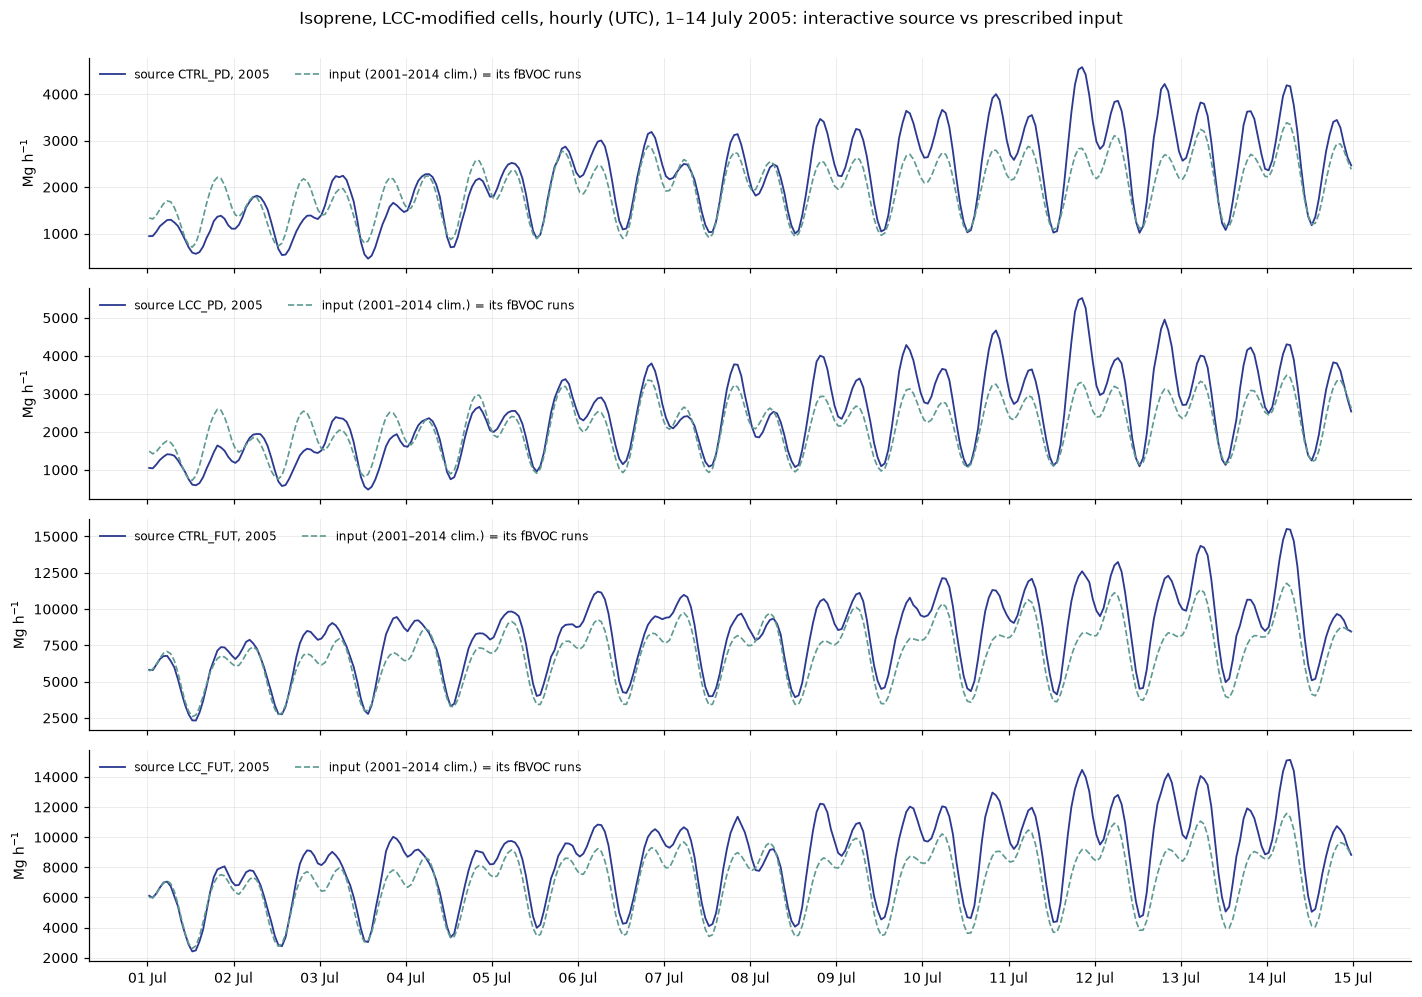

In [21]:
# 10.4b zoom: two weeks of July 2005, hourly, each source vs its input (LCC-modified cells)
y = 2005
t = pd.date_range(f"{y}-01-01 00:30", periods=8760, freq="h")
s_ = (t >= f"{y}-07-01") & (t < f"{y}-07-15")
fig, axes = plt.subplots(len(SOURCES), 1, figsize=(13, 9), sharex=True)
for ax, s in zip(axes, SOURCES):
    x = TS_S[s][SRC_YEARS.index(y), 0].reshape(8760, 2).mean(-1)
    e = ems_ts(s)[0].reshape(8760, 2).mean(-1)
    ax.plot(t[s_], x[s_], color=NAVY, lw=1.2, label=f"source {s}, {y}")
    ax.plot(t[s_], e[s_], color=TEAL, lw=1.1, ls="--", label="input (2001–2014 clim.) = its fBVOC runs")
    ax.set_ylabel("Mg h$^{-1}$"); ax.grid(alpha=0.3, lw=0.5)
    ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.suptitle(f"Isoprene, LCC-modified cells, hourly (UTC), 1–14 July {y}: interactive source vs prescribed input", y=1.0)
fig.tight_layout()
fig.savefig(OUT / "figures/isoprene_fbvoc_vs_source_zoom_july2005.png", dpi=200, bbox_inches="tight")

### 10.5 Summary

Each production fBVOC run against the interactive run its isoprene comes from. Regions: LCC-modified cells / all cells ≥ 45°N. Evidence: tables above, `tables/isoprene_fbvoc_vs_source_*.csv`.

| Question | Answer |
|---|---|
| Is the input the source's 2001–2014 mean? | **Yes, exactly**: 30-min regional totals, max difference 0.0 % (10.4 check column); grid-cell composites in 10.1. |
| Does every fBVOC run emit the input, every month, 2001–2025? | **Yes**: all 8 runs, 300 months each, run h0 / input = −0.047 % in every month (constant offset, same as the 0.05 % of the replay test in section 8; probably the unit factor or the h0 step averaging, (b)). Runs sharing a source emit identical isoprene. |
| `LCC_FUT` input from the output-only rerun? | `LCC_FUT_HRBVOC` h0 = `LCC_FUT` h0 bit for bit (336 region-months). |
| Diurnal shape | **Unchanged**: JJA peak 13:15 local in the input, 12:45–13:15 in the source years; night share (18–06 h) 4.2 % input vs 4.0–4.5 % in the years (`CTRL_PD`, modified cells). |
| What the run misses, year to year | The JJA level of each source year departs from the input by SD 7–9 % (modified cells; 5–6 % ≥ 45°N), range about −16 % to +15 %, nearly the same at every daytime hour: **a level shift, not a timing change**. Annual totals: source SD 6–8 %, fBVOC 0 %. |
| Over 2015–2025 | The runs keep the 2001–2014 cycle while the source follows the 2015–2025 weather: fBVOC runs / source = +1.9 to +2.3 % for the PD sources and −0.5 to −1.4 % for the FUT sources (ratio of the 2015–2025 means), against −0.047 % over 2001–2014. |
| Hour-to-hour and day-to-day | The input reproduces 88–95 % of the source's 30-min variance and 95–98 % of the daily-mean variance (diurnal + seasonal cycle), but only **14–25 % of the day-to-day weather anomaly** (daily mean minus 31-day running mean): source anomaly SD 21–34 % of the mean, input 10–12 % (what is left of 14 years of weather in the average, not the weather of the day). Daily-mean RMSE 24–39 % of the mean. |

**Reading for the artefact (b):** the fBVOC runs get the right mean, seasonal and diurnal cycle of isoprene, with no bias over 2001–2014. What they lose is the coupling to the weather of the day and year, which in the source is large (±25–35 % day to day, ±7–9 % between summers). Any artefact (interactive − prescribed) therefore comes from that missing covariance with weather, plus a ~2 % mean offset in PD over 2015–2025, not from the diurnal timing.
